In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns

import joblib  # to save models and scalers


In [2]:
df = pd.read_csv("../data/car_sales_preprocessed_2.csv")
print("Shape:", df.shape)
df.head()

Shape: (761973, 236)


,quarter,Brand_LE,Model_LE,Body Type_LE,Year_2022,Year_2023,Gov_اسيوط,Gov_الاسكندرية,Gov_الاسماعيلية,Gov_الاقصر,...,TU_وحده مرور حلوان,TU_وحده مرور سنورس,TU_وحده مرور سيدى سالم,TU_وحده مرور شبراخيت,TU_وحده مرور فارسكور,TU_وحده مرور قطور,TU_وحده مرور مرسى علم,TU_وحده مرور ميناء دمياط البحرى,TU_وحده مرور نادى القضاه,TU_وحده مرور نادى القضاه - طنطا
0,1,68,393,6,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1,56,329,8,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1,56,626,8,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1,68,393,6,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1,68,393,6,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False


In [3]:
# Find all one-hot governorate columns
gov_ohe_cols = [c for c in df.columns if c.startswith("Gov_")]

# Create a single label column for governorates
df["Gov_Label"] = df[gov_ohe_cols].idxmax(axis=1).str.replace("Gov_", "")

df[["Gov_Label"] + gov_ohe_cols].head()

,Gov_Label,Gov_اسيوط,Gov_الاسكندرية,Gov_الاسماعيلية,Gov_الاقصر,Gov_البحر الاحمر,Gov_البحيرة,Gov_الجيزة,Gov_الدقهلية,Gov_السويس,...,Gov_الوادي الجديد,Gov_بني سويف,Gov_بورسعيد,Gov_جنوب سيناء,Gov_دمياط,Gov_سوهاج,Gov_شمال سيناء,Gov_قنا,Gov_كفر الشيخ,Gov_مرسي مطروح
0,الاسكندرية,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,الاسكندرية,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,الاسكندرية,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,الاسكندرية,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,الاسكندرية,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [4]:
# 1) Total sales count per governorate
gov_counts = df.groupby("Gov_Label").size().reset_index(name="sales_count")

# 2) Absolute counts instead of proportions
brand_cols    = [c for c in df.columns if c.startswith("Brand_")]
body_cols     = [c for c in df.columns if c.startswith("BodyType_")]
tu_cols       = [c for c in df.columns if c.startswith("TU_")]

# Aggregate absolute counts per governorate
agg_abs = df.groupby("Gov_Label")[brand_cols + body_cols + tu_cols].sum()

# Add derived features
agg_abs["total_body_types"] = agg_abs[body_cols].sum(axis=1)
# Fix dominant_body_type - handle cases where all values are zero
dominant_body_type = []
for idx, row in agg_abs[body_cols].iterrows():
    if row.sum() > 0:
        dominant = row.idxmax().str.replace("BodyType_", "") if hasattr(row.idxmax(), 'str') else row.idxmax().replace("BodyType_", "")
    else:
        dominant = "None"
    dominant_body_type.append(dominant)
agg_abs["dominant_body_type"] = dominant_body_type
agg_abs["brand_diversity"] = (agg_abs[brand_cols] > 0).sum(axis=1)
agg_abs["tu_diversity"] = (agg_abs[tu_cols] > 0).sum(axis=1)

# Merge total sales count
gov_summary = gov_counts.merge(agg_abs, left_on="Gov_Label", right_index=True)

display(gov_summary.head())

,Gov_Label,sales_count,Brand_LE,TU_مجلس الدولة,TU_منفذ جمـارك القاهـرة - تسيير,TU_منفذ مرور موانى بورسعيد,TU_منفذ ميناء الاسكندرية,TU_منفذ ميناء السويس,TU_منفذ ميناء سفاجا,TU_منفذ ميناء نويبـــع,...,TU_وحده مرور فارسكور,TU_وحده مرور قطور,TU_وحده مرور مرسى علم,TU_وحده مرور ميناء دمياط البحرى,TU_وحده مرور نادى القضاه,TU_وحده مرور نادى القضاه - طنطا,total_body_types,dominant_body_type,brand_diversity,tu_diversity
0,اسيوط,22432,1060669,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.0,None,1,11
1,الاسكندرية,52516,2640232,0,0,0,14,0,0,0,...,0,0,0,0,0,0,0.0,None,1,9
2,الاسماعيلية,14329,710774,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.0,None,1,6
3,الاقصر,6504,291979,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.0,None,1,3
4,البحر الاحمر,13578,640236,0,0,0,0,0,21,0,...,0,0,1058,0,0,0,0.0,None,1,6


In [5]:
# Prepare data for clustering - drop non-numeric columns
columns_to_drop = ["Gov_Label", "dominant_body_type"]
# Only drop columns that exist
existing_columns = [col for col in columns_to_drop if col in gov_summary.columns]
X = gov_summary.drop(columns=existing_columns)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Save scaler
joblib.dump(scaler, "../models/gov_scaler.joblib")
print("Scaler saved as gov_scaler.joblib")
print(f"Data shape after preprocessing: {X.shape}")
print(f"Dropped columns: {existing_columns}")
print(f"Features used: {list(X.columns)}")

Scaler saved as gov_scaler.joblib
Data shape after preprocessing: (26, 209)
Dropped columns: ['Gov_Label', 'dominant_body_type']
Features used: ['sales_count', 'Brand_LE', 'TU_مجلس الدولة', 'TU_منفذ جمـارك القاهـرة - تسيير', 'TU_منفذ مرور موانى بورسعيد', 'TU_منفذ ميناء الاسكندرية', 'TU_منفذ ميناء السويس', 'TU_منفذ ميناء سفاجا', 'TU_منفذ ميناء نويبـــع', 'TU_وحدة القوات المسلحـة', 'TU_وحدة خدمات الشرطة', 'TU_وحدة دمياط الجديدة', 'TU_وحدة عين الصيــرة', 'TU_وحدة ق.م مصطفى كامل', 'TU_وحدة مرور 6 اكتوبر', 'TU_وحدة مرور أبو المطامير', 'TU_وحدة مرور أبوحماد', 'TU_وحدة مرور أبوكبير', 'TU_وحدة مرور أسوان', 'TU_وحدة مرور أوسيـم', 'TU_وحدة مرور إدفو', 'TU_وحدة مرور إدكو', 'TU_وحدة مرور إسنـا', 'TU_وحدة مرور إمبابة', 'TU_وحدة مرور إيتاي البارود', 'TU_وحدة مرور ابشواى', 'TU_وحدة مرور ابو تيج', 'TU_وحدة مرور ابورديس', 'TU_وحدة مرور ابوقرقاص', 'TU_وحدة مرور ابيـس', 'TU_وحدة مرور اجا', 'TU_وحدة مرور اسيوط', 'TU_وحدة مرور اسيوط الجديدة', 'TU_وحدة مرور اشمــون', 'TU_وحدة مرور اطســا', 'TU_وحدة مرور الأ

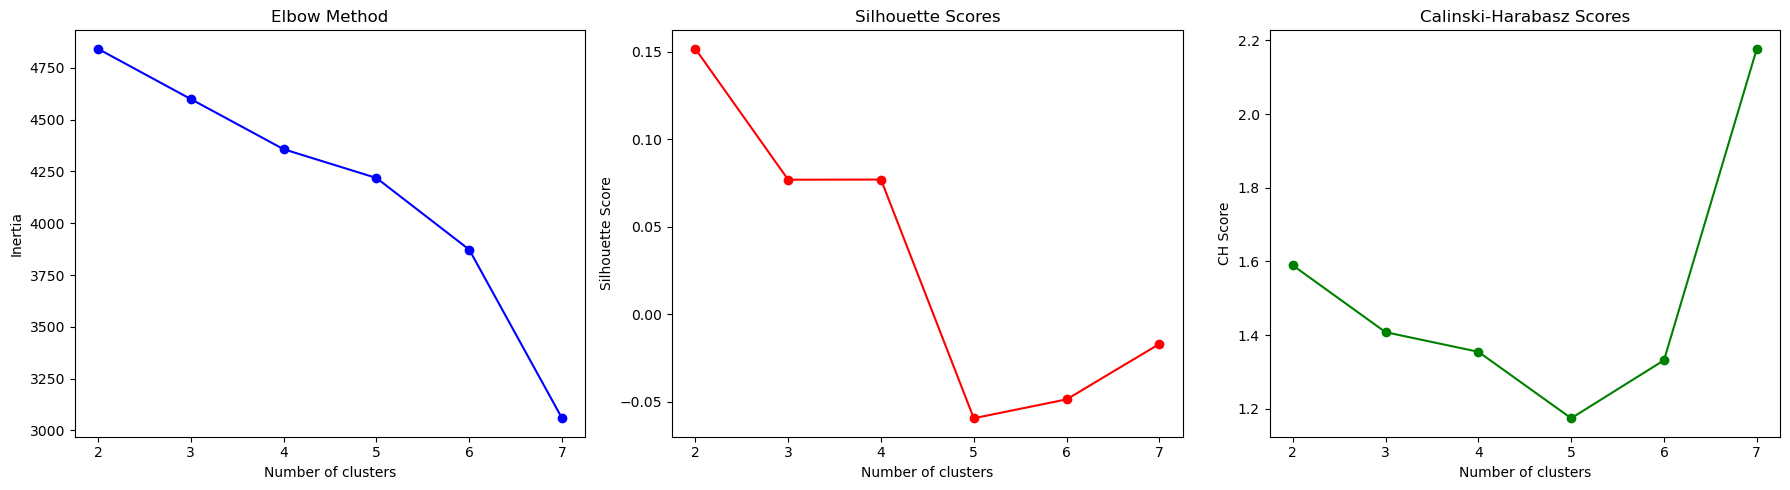

k=2 → Silhouette: 0.152, CH: 2
k=3 → Silhouette: 0.077, CH: 1
k=4 → Silhouette: 0.077, CH: 1
k=5 → Silhouette: -0.059, CH: 1
k=6 → Silhouette: -0.049, CH: 1
k=7 → Silhouette: -0.017, CH: 2


In [6]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# Reduce dimensions first
pca = PCA(n_components=0.95)  # Keep 95% variance
X_pca = pca.fit_transform(X_scaled)

# Elbow method
inertia = []
silhouette_scores = []
ch_scores = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_pca)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_pca, labels))
    ch_scores.append(calinski_harabasz_score(X_pca, labels))

# Plot results
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(K_range, inertia, "bo-")
ax1.set_title("Elbow Method")
ax1.set_xlabel("Number of clusters")
ax1.set_ylabel("Inertia")

ax2.plot(K_range, silhouette_scores, "ro-")
ax2.set_title("Silhouette Scores")
ax2.set_xlabel("Number of clusters")
ax2.set_ylabel("Silhouette Score")

ax3.plot(K_range, ch_scores, "go-")
ax3.set_title("Calinski-Harabasz Scores")
ax3.set_xlabel("Number of clusters")
ax3.set_ylabel("CH Score")

plt.tight_layout()
plt.show()

# Print detailed scores
for k in K_range:
    print(f"k={k} → Silhouette: {silhouette_scores[k-2]:.3f}, CH: {ch_scores[k-2]:.0f}")

In [7]:
# Try different clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

# 1) KMeans with PCA
k = 3  # Based on evaluation
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca)

# 2) Hierarchical clustering
hc = AgglomerativeClustering(n_clusters=k, linkage='ward')
hc_labels = hc.fit_predict(X_pca)

# 3) Compare results
print("KMeans Silhouette:", silhouette_score(X_pca, kmeans_labels))
print("Hierarchical Silhouette:", silhouette_score(X_pca, hc_labels))

# Use the better performing method
if silhouette_score(X_pca, hc_labels) > silhouette_score(X_pca, kmeans_labels):
    gov_summary["cluster"] = hc_labels
    print("Using Hierarchical Clustering")
else:
    gov_summary["cluster"] = kmeans_labels
    print("Using KMeans")

joblib.dump(kmeans, "../models/gov_clustering_model.joblib")
print("Model saved as gov_clustering_model.joblib")

KMeans Silhouette: 0.07696042345515394
Hierarchical Silhouette: 0.23862768940520315
Using Hierarchical Clustering
Model saved as gov_clustering_model.joblib


In [8]:
# Label clusters by average sales_count
cluster_order = gov_summary.groupby("cluster")["sales_count"].mean().sort_values().index.tolist()

label_map = {
    cluster_order[0]: "Low",
    cluster_order[1]: "Mid",
    cluster_order[2]: "High"
}

gov_summary["sales_segment"] = gov_summary["cluster"].map(label_map)

display(gov_summary)

,Gov_Label,sales_count,Brand_LE,TU_مجلس الدولة,TU_منفذ جمـارك القاهـرة - تسيير,TU_منفذ مرور موانى بورسعيد,TU_منفذ ميناء الاسكندرية,TU_منفذ ميناء السويس,TU_منفذ ميناء سفاجا,TU_منفذ ميناء نويبـــع,...,TU_وحده مرور مرسى علم,TU_وحده مرور ميناء دمياط البحرى,TU_وحده مرور نادى القضاه,TU_وحده مرور نادى القضاه - طنطا,total_body_types,dominant_body_type,brand_diversity,tu_diversity,cluster,sales_segment
0,اسيوط,22432,1060669,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,11,0,Low
1,الاسكندرية,52516,2640232,0,0,0,14,0,0,0,...,0,0,0,0,0.0,None,1,9,0,Low
2,الاسماعيلية,14329,710774,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,6,0,Low
3,الاقصر,6504,291979,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,3,0,Low
4,البحر الاحمر,13578,640236,0,0,0,0,0,21,0,...,1058,0,0,0,0.0,None,1,6,0,Low
5,البحيرة,22817,1143085,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,13,0,Low
6,الجيزة,110844,5379764,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,15,2,Mid
7,الدقهلية,29966,1526825,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,9,0,Low
8,السويس,7868,393016,0,0,0,0,91,0,0,...,0,0,0,0,0.0,None,1,2,0,Low
9,الشرقية,37082,1813722,0,0,0,0,0,0,0,...,0,0,0,0,0.0,None,1,12,0,Low


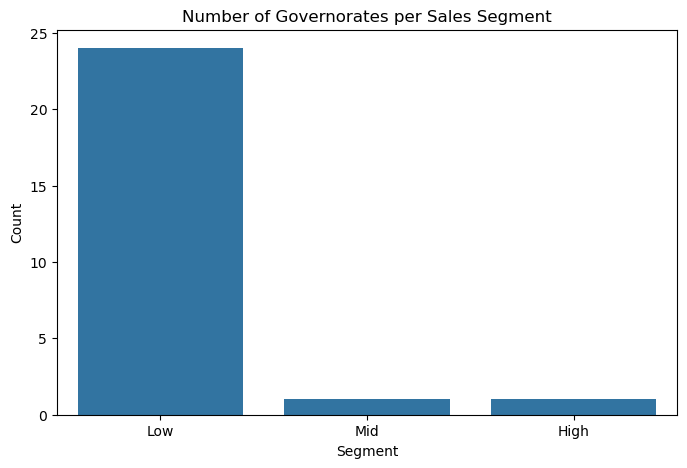

In [9]:
plt.figure(figsize=(8,5))
sns.countplot(x="sales_segment", data=gov_summary.reset_index())
plt.title("Number of Governorates per Sales Segment")
plt.xlabel("Segment")
plt.ylabel("Count")
plt.show()


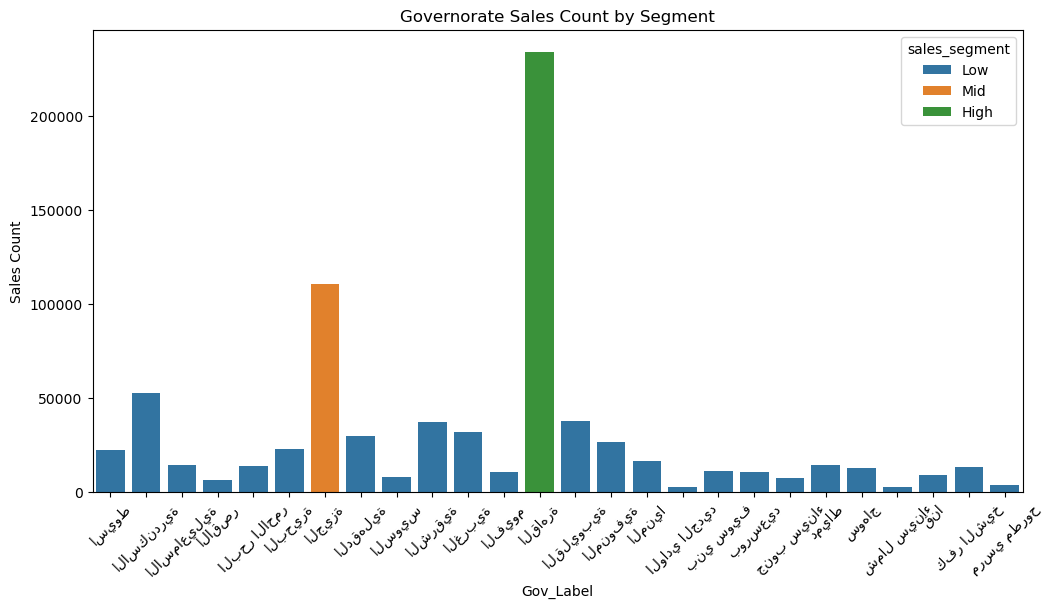

In [10]:
plt.figure(figsize=(12,6))
sns.barplot(
    x=gov_summary["Gov_Label"],
    y="sales_count",
    hue=gov_summary["sales_segment"],
    data=gov_summary.reset_index()
)
plt.xticks(rotation=45)
plt.title("Governorate Sales Count by Segment")
plt.ylabel("Sales Count")
plt.show()

Top 10 Most Important Features:
   feature  importance
0     PC_1    0.151596
1     PC_2    0.122676
2     PC_3    0.122161
17   PC_18    0.078168
3     PC_4    0.064262
4     PC_5    0.057608
21   PC_22    0.056706
19   PC_20    0.055949
13   PC_14    0.047406
5     PC_6    0.042086


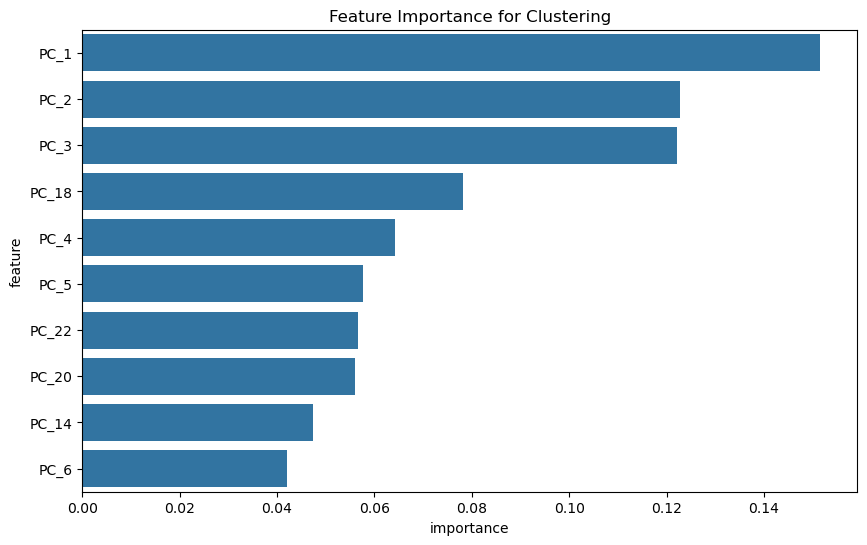

In [11]:
# Analyze what features drive the clustering
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_pca, gov_summary["cluster"])

# Get feature importance
feature_importance = pd.DataFrame({
    'feature': [f'PC_{i+1}' for i in range(X_pca.shape[1])],
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance.head(10), x='importance', y='feature')
plt.title('Feature Importance for Clustering')
plt.show()